# ¿Llegaremos a las metas de crecimiento en 2026?
Análisis reproducible de la economía mexicana. Todas las cifras provienen de boletines oficiales del INEGI (transcritas en `./data`), del Paquete Económico 2027 (SHCP) y de la Encuesta Citi (6-oct-2026).

| Archivo | Fuente |
|---|---|
| `igae_variacion_mensual.csv` | [IGAE julio 2026](https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/igae/igae2026_09.pdf), [IOAE agosto 2026](https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/ioae/ioae2026_09.pdf) |
| `pib_nominal_sectores_2t2026.csv` | [PIB trimestral a precios corrientes 2T-2026](https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/pibt/pib_Pcorr2026_08.pdf) |
| `igae_sectores_julio2026.csv` | [IGAE julio 2026, cuadro 2 (cifras originales)](https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/igae/igae2026_09.pdf) |
| `productividad_costo_2t2026.csv` | [IPL-CUMO 2T-2026, cuadros 5 y 6](https://www.inegi.org.mx/contenidos/saladeprensa/boletines/2026/iplcumo/iplcumo2026_09.pdf) |


In [1]:
import pandas as pd
from IPython.display import Image, display
import graficas_igae as g

## 1. El pulso mes a mes: ¿vamos hacia la meta?

,PERIODO,VARIACION_MENSUAL,TIPO,LIM_INF,LIM_SUP
18,2026-01-01,-1.0,observado,NaN,NaN
19,2026-02-01,0.3,observado,NaN,NaN
20,2026-03-01,0.5,observado,NaN,NaN
21,2026-04-01,1.5,observado,NaN,NaN
22,2026-05-01,-0.3,observado,NaN,NaN
23,2026-06-01,0.0,observado,NaN,NaN
24,2026-07-01,0.8,observado,NaN,NaN
25,2026-08-01,0.1,estimado,-1.0,1.3


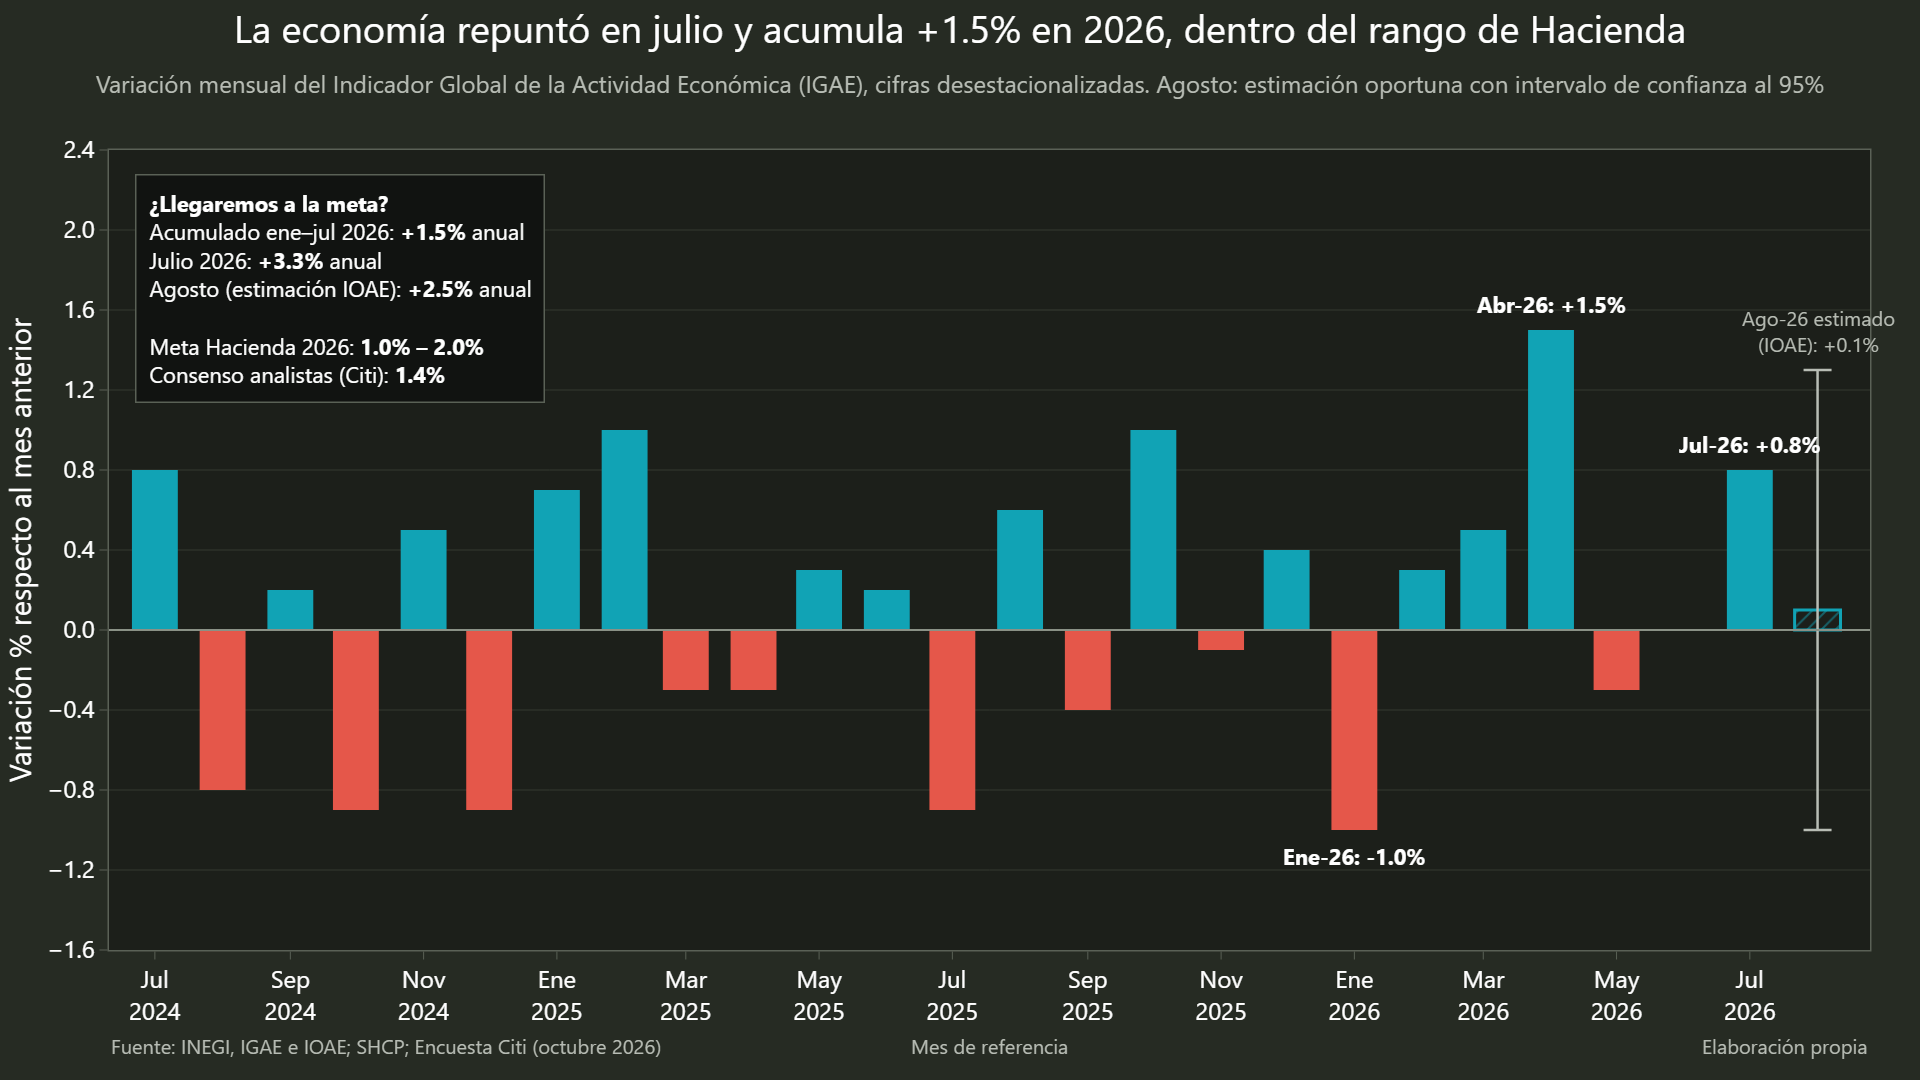

In [2]:
display(pd.read_csv('./data/igae_variacion_mensual.csv').tail(8))
g.plot_pulso_mensual()
display(Image('./imgs/1_igae_pulso_mensual.png', width=960))

## 2. ¿Quién pesa en el PIB? (verifica el 64% / 30% del borrador)

GRUPO
Primarias       4.051094
Secundarias    32.590075
Terciarias     63.358831
Name: MILLONES_PESOS, dtype: float64
Manufactura + construcción: 27.8 %


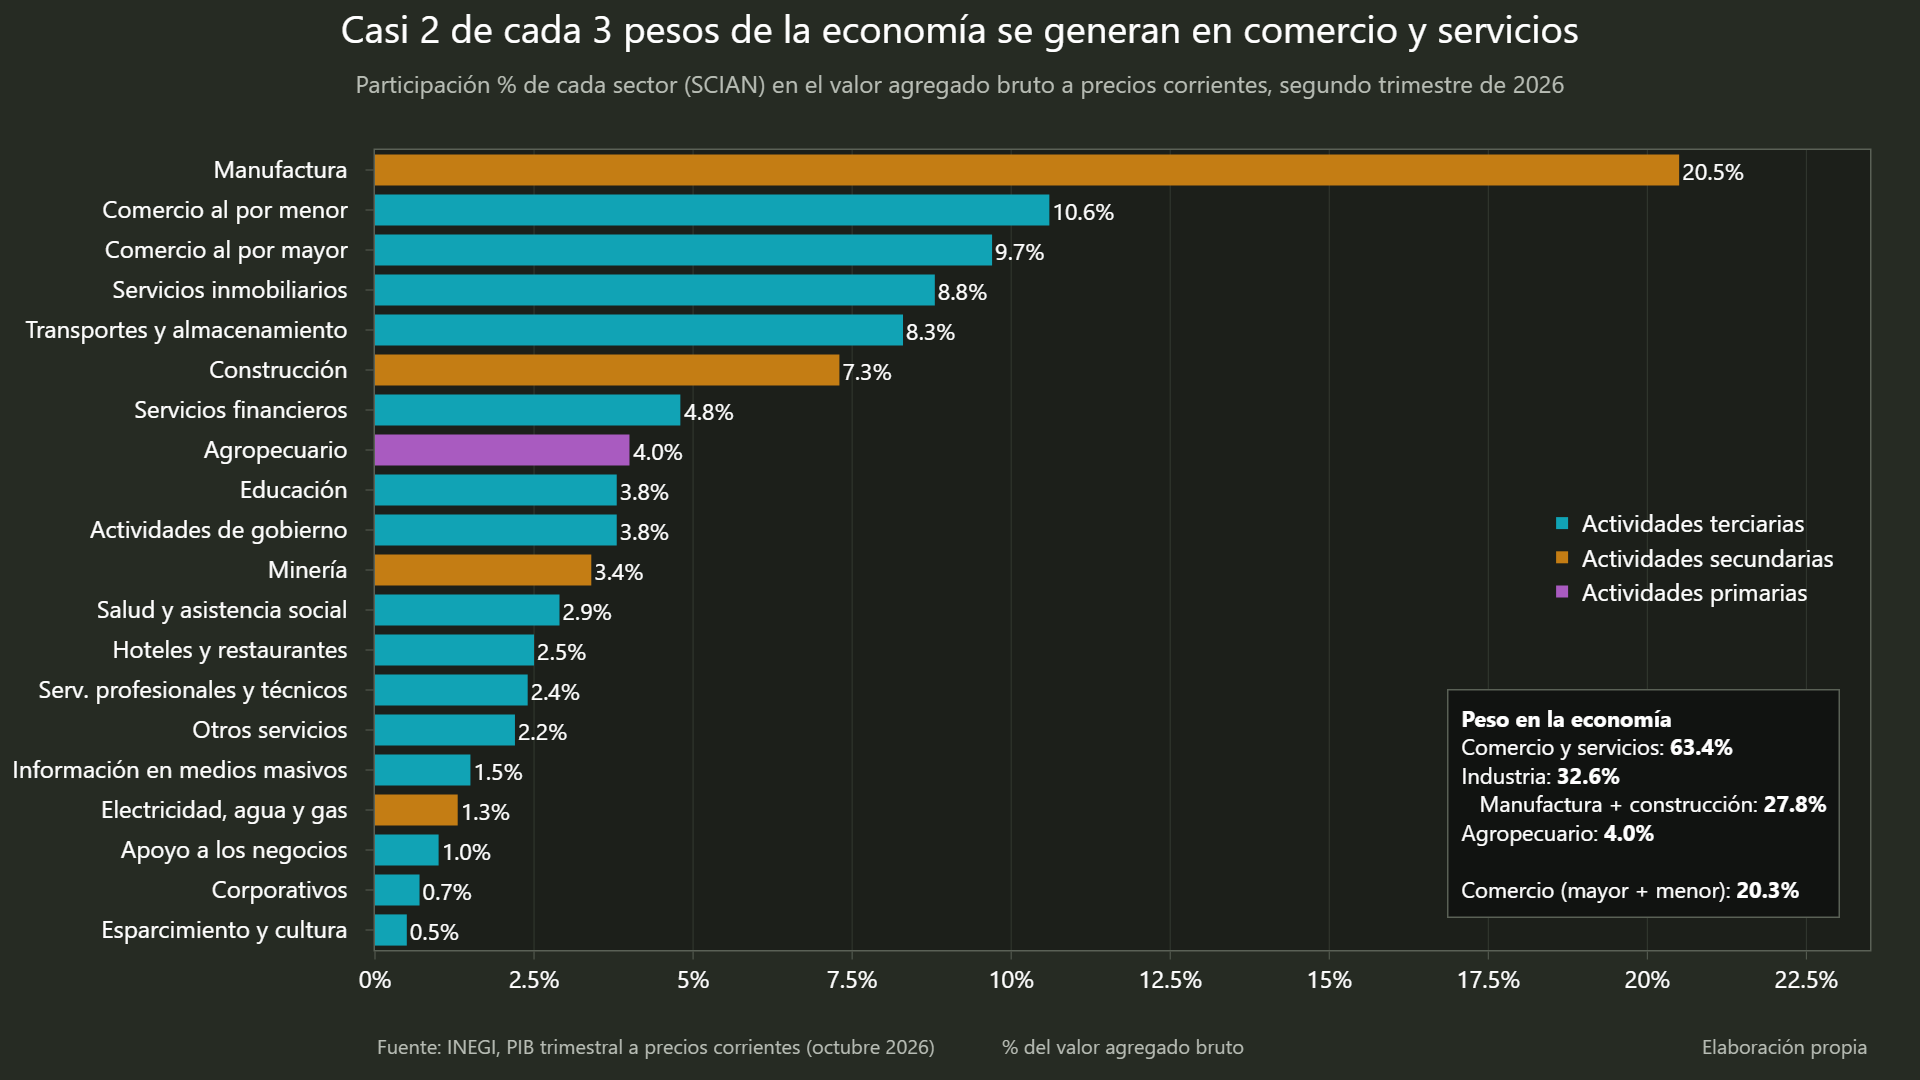

In [3]:
pib = pd.read_csv('./data/pib_nominal_sectores_2t2026.csv')
print(pib.groupby('GRUPO')['MILLONES_PESOS'].sum() / pib['MILLONES_PESOS'].sum() * 100)
print('Manufactura + construcción:', pib.loc[pib.SECTOR.isin(['Manufactura', 'Construcción']), 'PARTICIPACION'].sum(), '%')
g.plot_peso_sectores()
display(Image('./imgs/2_peso_sectores_pib.png', width=960))

## 3. El benchmark para tu P&L: crecimiento por sector

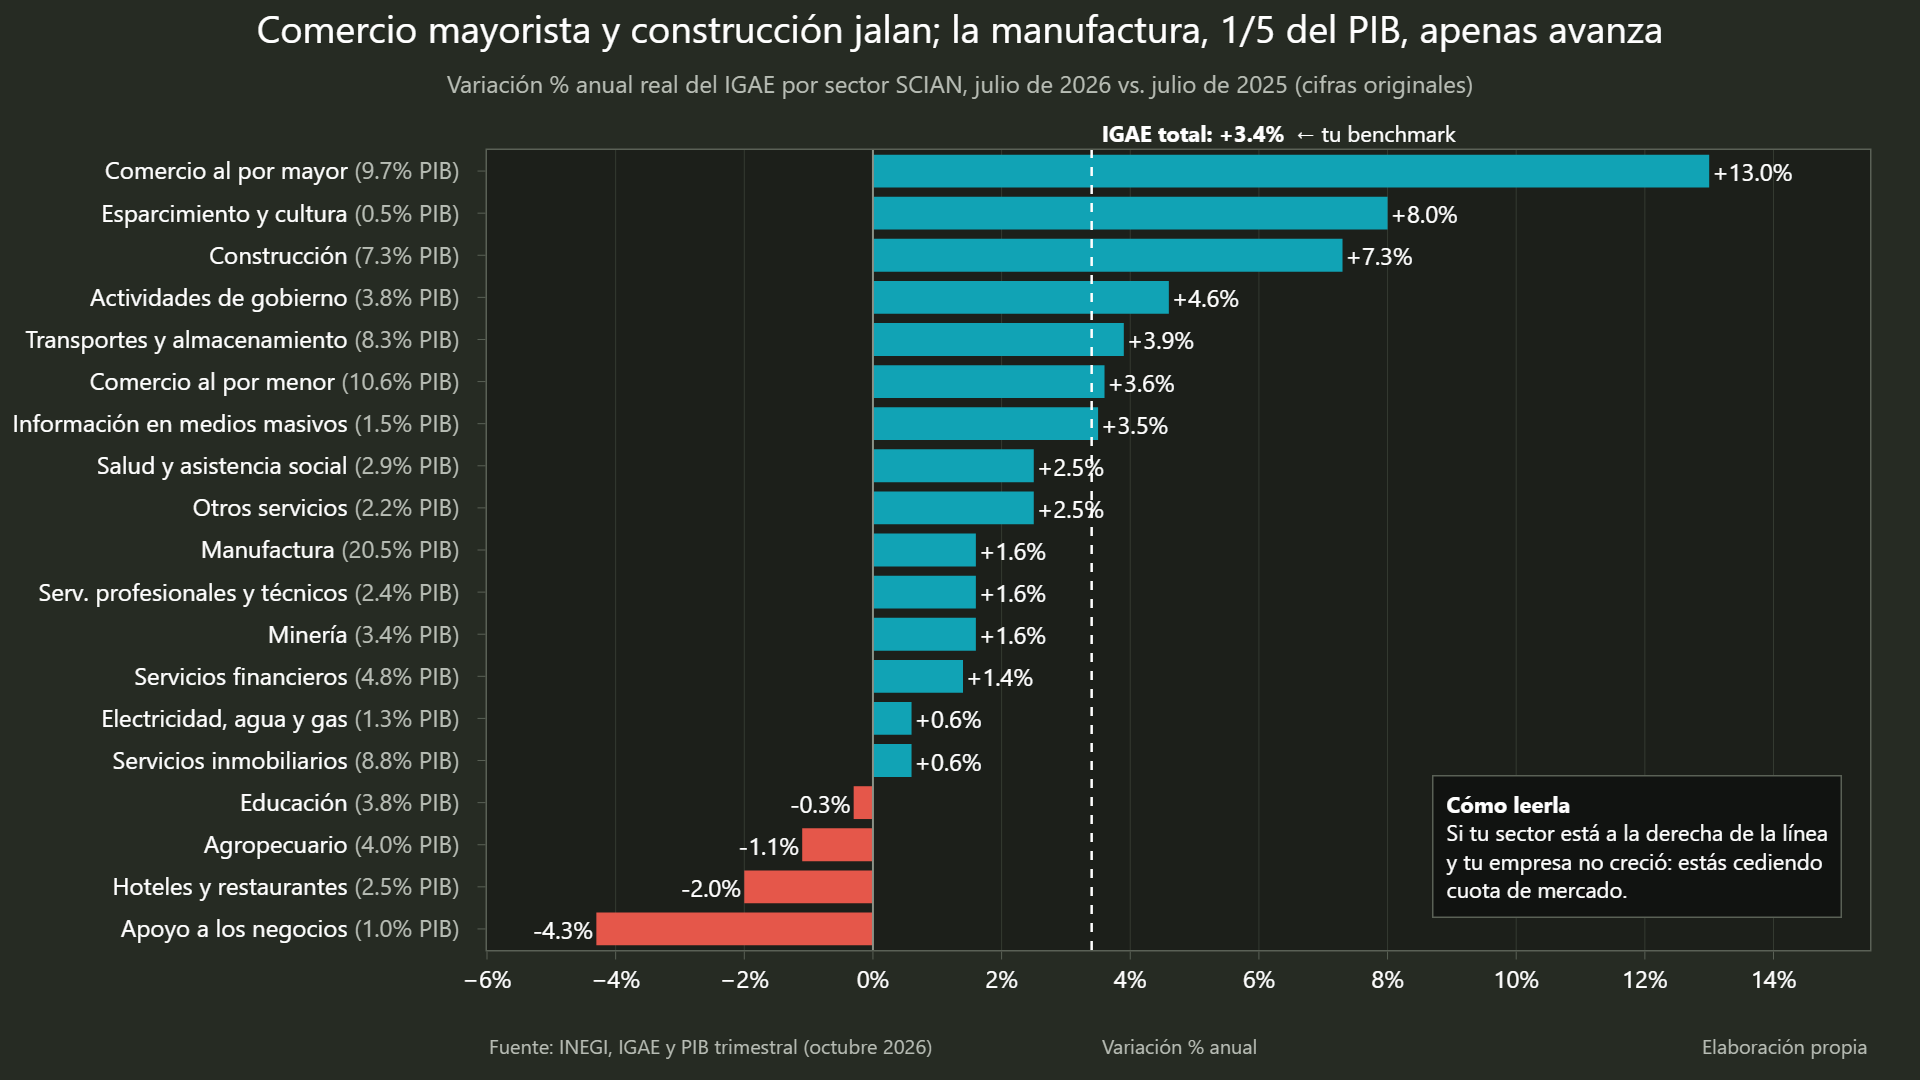

In [4]:
g.plot_crecimiento_sectores()
display(Image('./imgs/3_crecimiento_sectores_julio.png', width=960))

## 4. Volumen vs. productividad vs. costo laboral

,SECTOR,VOLUMEN,PERSONAL_U_HORAS,PRODUCTIVIDAD,REMUNERACION_REAL,COSTO_UNITARIO
0,Comercio al por mayor,12.3,-0.6,13.0,0.7,-10.9
1,Construcción,5.6,-0.3,5.9,1.2,-4.4
2,Comercio al por menor,2.8,0.2,2.7,6.2,3.5
3,Manufactura,-0.2,-1.6,1.5,1.3,-0.2
4,Servicios privados no financieros,-2.0,-2.2,0.2,2.2,2.0


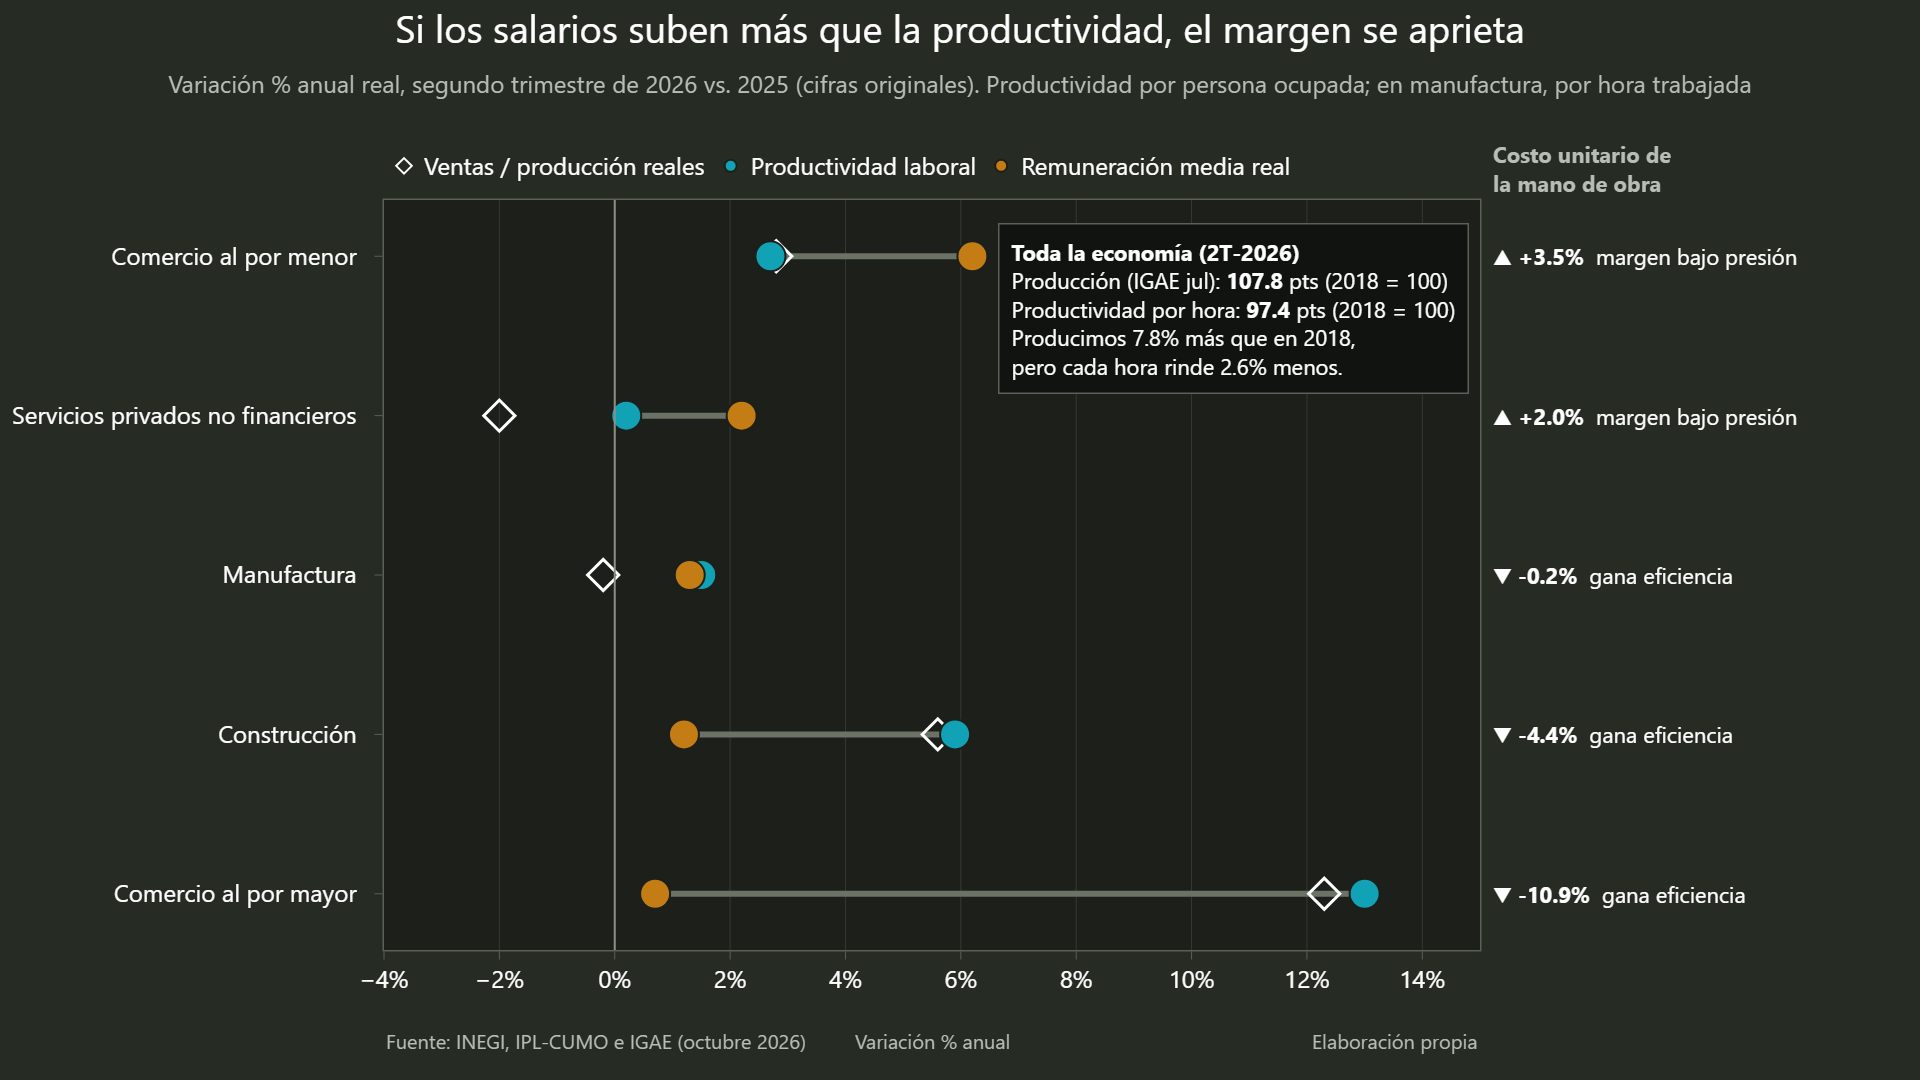

In [5]:
display(pd.read_csv('./data/productividad_costo_2t2026.csv'))
g.plot_productividad_costos()
display(Image('./imgs/4_productividad_vs_costos.png', width=960))